## Problema - Organización y búsqueda de productos en una tienda

**Instrucción:** completa esta plantilla con tu diseño y desarrollo. Evita incluir soluciones generadas automáticamente.



In [ ]:
# @title Ingrese datos
nombre_estudiante = "Anderson Varela" 
carnet = 1000116567


## 1) Descripción del problema **[1 pts]**

Una empresa solicita un programa para poder organizar sus prioridades de eventos tecnicos y conectar varios dispositivos con la menor cantidad de cable posible para una mejor optimizacion de los recursos 
entonces solicitan que muestre la organizacion de las listas con el max heap y como queda su arbol despues de eso y poder ver las tareas con mayor prioridad dependiendo de que tanto sea su peso y al final su arbol de expansion minimo dando la longitud total de cable usada y cual es el peso de cada dispositivo



## 2) Requerimientos **[2 pts]**

REQUERIMIENTOS FUNCIONALES

RF N01:  Tener la lista de tareas y sus respectivos codigos con sus prioridades ya establecidas

RF N02: El programa debe implementar HEAP para los eventos y para procesar tareas

RF N03: El programa debe generar una grafica a partir de los datos generados por el HEAP

REQUERIMIENTOS NO FUNCIONALES

RNF N01: Tener los dispositivos que se usaran para conectar

RNF N02: Tener la cantidad de cable suficiente para conectar cada disppositivo





## 3) Historias de usuario **[2 pts]**

Yo como administrador de eventos en la empresa quiero añadir un nuevo evento que tenga prioridad mayor a todos los demas eventos

Criterio de aceptacion:Codigo del evento-Titulo-Prioridad (valor mayor a 12)

Criterio de falla:Codigos no validos-cosas que no vayan con el formato de la cola de prioridad)

Un trabajador del area de seguridad solicita añadir un nuevo dispositivo llamado microfono

Criterios de aceptacion: Una ID que sea una letra mayuscula siguiendo el formato, posicion en X y en Y

Criterio de falla: ID numerica, coordenadas siendo letras o simbolos

Un analista de eventos decide subir la prioridad de el evento "Generar Respaldo" a 10 igual que reparar sensor y sube tambien la de "Actualizar software" a ese valor

Criterios de Aceptacion: Prioridad valida, numero coherente con las demas prioridades

Criterios de falla:Prioridad escritra de forma de letra o simbolo





## 4) Diagramas de flujo **[5 pts]**

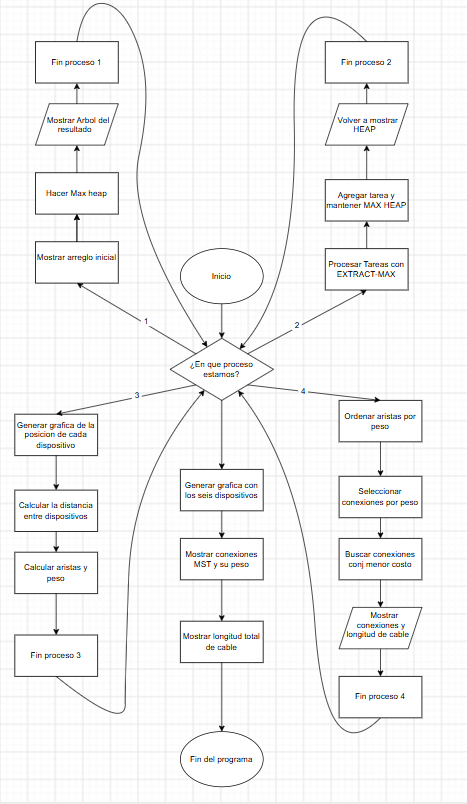

El programa inicia y consulta el numero del proceso,como esta inicaido apenas, va por el primero donde se realiza el max heap y se muestra al usuario el arbol resultante, luego se vuelve a preguntar el numero del proceso llendo al segundo donde se usa extract max para sacar las tareas con mayor prioridad y se añade una nueva sin perder el max heap anteriormente desarrollado y manteniendo sus propiedades, ya con el tercer proceso observamos que posicion tiene cada dispositivo y que tan lejos estan unos de otros ,seguido a eso calcula sus aristas mas el peso de las mismas y da paso al proceso numero cuatro el cual las ordena por peso y busca cuales conexiones tienen menor costo para finalmente mostrar las conexiones y su cantidad de cable dando paso al proceso 5.En este proceso se le muestra al usuario una grafica con cada dispositivo,sus conexiones,y la longitud total de cable utlizada


### 5) Análisis de complejidad **[15 pts]**
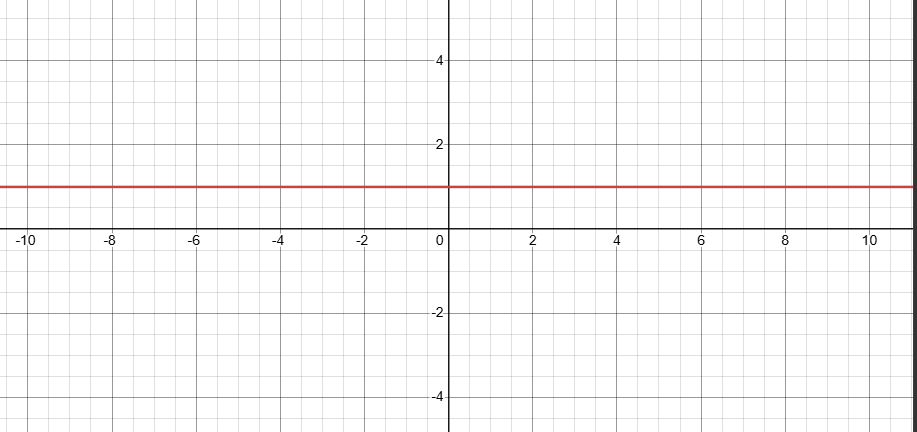

Mejor caso: O(1)

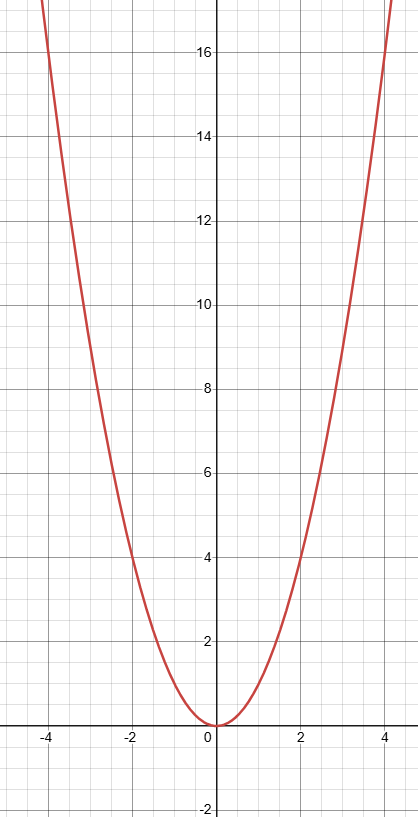

Peor caso: O(x^2)



## 6) Código funcional **[15 pts]**
Incluye tu implementación completa.

No pegues código incompleto; debe ser ejecutable.


--- PUNTO 1 ---
Arreglo inicial: [[6, 'T01', 'Configurar servidor'], [10, 'T02', 'Reparar sensor'], [4, 'T03', 'Actualizar software'], [8, 'T04', 'Revisar cámara'], [3, 'T05', 'Generar respaldo'], [7, 'T06', 'Configurar alarma']]
Max-Heap resultante: [[10, 'T02', 'Reparar sensor'], [8, 'T04', 'Revisar cámara'], [7, 'T06', 'Configurar alarma'], [6, 'T01', 'Configurar servidor'], [3, 'T05', 'Generar respaldo'], [4, 'T03', 'Actualizar software']]
Árbol del Heap:
Nivel 0: [[10, 'T02', 'Reparar sensor']]
Nivel 1: [[8, 'T04', 'Revisar cámara'], [7, 'T06', 'Configurar alarma']]
Nivel 2: [[6, 'T01', 'Configurar servidor'], [3, 'T05', 'Generar respaldo'], [4, 'T03', 'Actualizar software']]

--- PUNTO 2 ---
Tarea 1 procesada: [10, 'T02', 'Reparar sensor']
Heap actual: [[8, 'T04', 'Revisar cámara'], [6, 'T01', 'Configurar servidor'], [7, 'T06', 'Configurar alarma'], [4, 'T03', 'Actualizar software'], [3, 'T05', 'Generar respaldo']]
Tarea 2 procesada: [8, 'T04', 'Revisar cámara']
Heap actual: [[7,

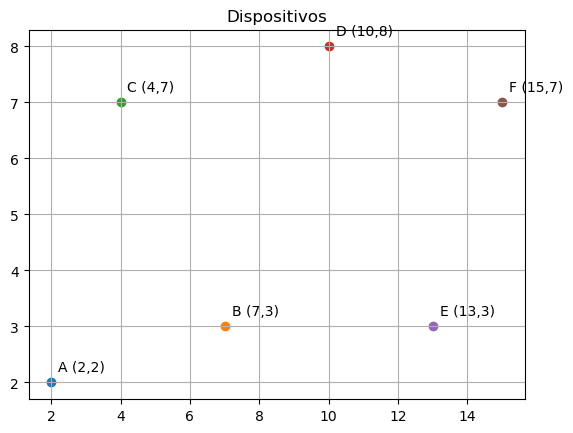


--- PUNTO 4 ---
Conexión E-F: 4.47
Conexión B-C: 5.00
Conexión A-B: 5.10
Conexión D-F: 5.10
Conexión B-D: 5.83
Longitud total de cable: 25.50

--- PUNTO 5 ---


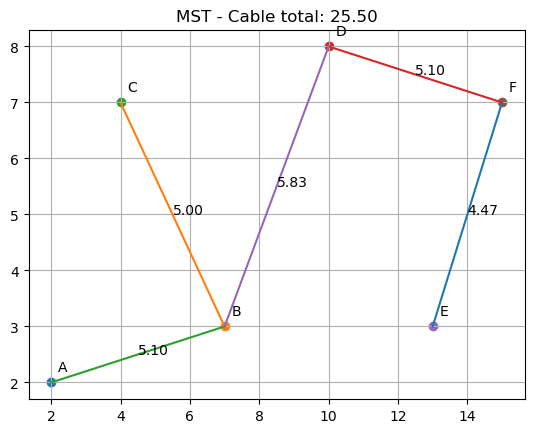

In [2]:
import math
import matplotlib.pyplot as plt

# Max heap
tareas = [
    [6, "T01", "Configurar servidor"],
    [10, "T02", "Reparar sensor"],
    [4, "T03", "Actualizar software"],
    [8, "T04", "Revisar cámara"],
    [3, "T05", "Generar respaldo"],
    [7, "T06", "Configurar alarma"],
]


def max_heapify(heap, n, i):
  mayor = i
  izq = 2 * i + 1
  der = 2 * i + 2

  if izq < n and heap[izq][0] > heap[mayor][0]:
    mayor = izq
  if der < n and heap[der][0] > heap[mayor][0]:
    mayor = der

  if mayor != i:
    heap[i], heap[mayor] = heap[mayor], heap[i]
    max_heapify(heap, n, mayor)


def build_max_heap(lista):
  heap = lista.copy()
  n = len(heap)
  for i in range(n // 2 - 1, -1, -1):
    max_heapify(heap, n, i)
  return heap


def ver_arbol(heap):
  nivel = 0
  inicio = 0
  while inicio < len(heap):
    fin = inicio + (2**nivel)
    print(f"Nivel {nivel}:", heap[inicio:fin])
    inicio = fin
    nivel += 1


print("--- PUNTO 1 ---")
print("Arreglo inicial:", tareas)
heap = build_max_heap(tareas)
print("Max-Heap resultante:", heap)
print("Árbol del Heap:")
ver_arbol(heap)


#Extraer el MAX
def extract_max(heap):
  maximo = heap[0]
  ultimo = heap.pop()
  if len(heap) > 0:
    heap[0] = ultimo
    max_heapify(heap, len(heap), 0)
  return maximo


print("\n--- PUNTO 2 ---")
t1 = extract_max(heap)
print("Tarea 1 procesada:", t1)
print("Heap actual:", heap)

t2 = extract_max(heap)
print("Tarea 2 procesada:", t2)
print("Heap actual:", heap)
heap.append([12, "T07", "Falla en sistema contra incendios"])
i = len(heap) - 1
while i > 0:
  padre = (i - 1) // 2
  if heap[i][0] > heap[padre][0]:
    heap[i], heap[padre] = heap[padre], heap[i]
    i = padre
  else:
    break

print("Heap después de insertar T07:", heap)


#Dispositivos y Distancias
print("\n--- PUNTO 3 ---")
devs = [
    ["A", "Servidor", 2, 2],
    ["B", "Cámara", 7, 3],
    ["C", "Sensor", 4, 7],
    ["D", "Alarma", 10, 8],
    ["E", "Router", 13, 3],
    ["F", "Panel", 15, 7],
]

aristas = []
for i in range(len(devs)):
  for j in range(i + 1, len(devs)):
    u = devs[i]
    v = devs[j]
    dist = math.sqrt((v[2] - u[2]) ** 2 + (v[3] - u[3]) ** 2)
    aristas.append([u[0], v[0], dist])
    print(f"{u[0]}-{v[0]}: {dist:.2f}")

plt.figure()
for d in devs:
  plt.scatter(d[2], d[3])
  plt.text(d[2] + 0.2, d[3] + 0.2, f"{d[0]} ({d[2]},{d[3]})")
plt.title("Dispositivos")
plt.grid(True)
plt.show()


print("\n--- PUNTO 4 ---")
# Ordenar aristas de menor a mayor distancia
aristas.sort(key=lambda x: x[2])

# Cada nodo empieza en su propio grupo
grupo = {d[0]: d[0] for d in devs}


def encontrar(n):
  while grupo[n] != n:
    n = grupo[n]
  return n


mst = []
total_cable = 0

for u, v, dist in aristas:
  gu = encontrar(u)
  gv = encontrar(v)
  if gu != gv:  # Si no forman ciclo
    grupo[gv] = gu
    mst.append([u, v, dist])
    total_cable += dist
    print(f"Conexión {u}-{v}: {dist:.2f}")
    if len(mst) == 5:
      break

print(f"Longitud total de cable: {total_cable:.2f}")


# ==========================================
# PUNTO 5: VISUALIZACIÓN FINAL DEL MST
# ==========================================
print("\n--- PUNTO 5 ---")
pos = {d[0]: (d[2], d[3]) for d in devs}

plt.figure()
for d in devs:
  plt.scatter(d[2], d[3])
  plt.text(d[2] + 0.2, d[3] + 0.2, d[0])

for u, v, dist in mst:
  x1, y1 = pos[u]
  x2, y2 = pos[v]
  plt.plot([x1, x2], [y1, y2])
  plt.text((x1 + x2) / 2, (y1 + y2) / 2, f"{dist:.2f}")

plt.title(f"MST - Cable total: {total_cable:.2f}")
plt.grid(True)
plt.show()

## 7) Tests aplicados **[15 pts]**

TypeError: max_heapify() missing 2 required positional arguments: 'n' and 'i'